# Analyse de la zone 14 — Auckland FC

Ce notebook décrit les traitements Python appliqués à quatre matchs d'Auckland FC pour étudier les passes, les frappes et les courses sans ballon associées à la zone 14.

Les fonctions réutilisables sont regroupées dans le fichier src/fonctions_zone14.py. Le notebook explique leur logique, les choix de préparation des données, les opérations Pandas et les représentations graphiques. Il présente les résultats calculés sans chercher à les interpréter sportivement, cette interprétation est réservée au notebook de synthèse.

Les données de position utilisées ici sont déjà normalisées dans le même sens d'attaque. Il n'est donc pas nécessaire d'inverser les coordonnées selon les équipes ou les mi-temps.

## 1. Importation et préparation des données

On importe les bibliothèques, puis les fonctions de `src/`. 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import sys
from pathlib import Path

#on retrouve le dossier src depuis la racine ou depuis notebooks
if Path('src').exists():
    sys.path.append('src')
else:
    sys.path.append('../src')

from fonctions_zone14 import (
    passes_depuis_zone14, 
    frappes_depuis_zone14,
    passes_vers_zone14, 
    courses_vers_zone14, 
    courses_depuis_zone14,
    tracer_terrain, 
    carte_actions, 
    bilan_match
)

### Chargement des événements et des informations de match
Les données de matchs sont chargées ci-dessous depuis l'espace S3 d'Onyxia. 

In [2]:
import s3fs
import json

fs = s3fs.S3FileSystem(
    endpoint_url='https://minio.lab.sspcloud.fr',
    client_kwargs={'region_name': 'us-east-1'}
)

#on charge les quatre fichiers JSON et Parquet
ids_matchs = [1886347, 1899585, 2015213, 2017461]
matchs = {}

for id_match in ids_matchs:
    events = pd.read_parquet(
        f's3://lfaivre/diffusion/{id_match}_dynamic_events.parquet',
        filesystem=fs
    )
    with fs.open(f's3://lfaivre/diffusion/{id_match}_match.json', 'r') as fichier:
        infos = json.load(fichier)

    nom_match = infos['home_team']['name'] + ' - ' + infos['away_team']['name']
    matchs[nom_match] = (infos, events)

id_auckland = 4177
print('Matchs chargés :', len(matchs))
for nom_match in matchs:
    print(nom_match)

Matchs chargés : 4
Auckland FC - Newcastle United Jets FC
Auckland FC - Wellington Phoenix FC
Western United - Auckland FC
Melbourne Victory Football Club - Auckland FC


## 2. Définition géométrique de la zone 14

La zone 14 est définie dans le script par un rectangle central situé devant la surface adverse. La fonction `bornes_zone14()` lit la longueur du terrain dans le fichier JSON et renvoie quatre limites : une borne minimale et maximale en longueur, puis une borne minimale et maximale en largeur.

Les coordonnées sont centrées sur le terrain. Les limites longitudinales retenues sont 17,5 mètres et la moitié de la longueur du terrain diminuée de 16,5 mètres, les limites latérales sont -11,33 et 11,33 mètres. Cette définition fixe un espace d'analyse constant à partir des dimensions de chaque terrain.

La fonction `dans_zone14()` compare ensuite les coordonnées d'un événement aux quatre bornes. Les comparaisons sont combinées avec l'opérateur & : un point est retenu seulement s'il satisfait simultanément les conditions sur x et y. La fonction fonctionne aussi bien sur une position isolée que sur des colonnes Pandas.

La fonction `tracer_terrain()` dessine les contours du terrain, la ligne médiane et le rectangle de la zone 14 à l'aide de `plt.plot()`.



Text(0.5, 1.0, 'Zone 14 : rectangle rouge')

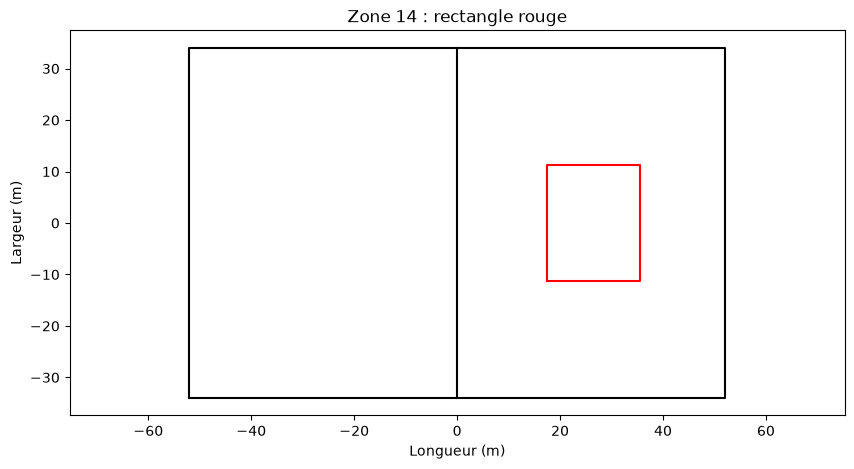

In [3]:
#on représente le terrain et la zone 14 sur le premier match
premier_match = list(matchs.values())[0][0]
plt.figure(figsize=(10, 5))
tracer_terrain(premier_match)
plt.title('Zone 14 : rectangle rouge')

## 3. Construction d'un bilan par match

La fonction `bilan_match()` du script réunit plusieurs indicateurs dans un dictionnaire. Elle commence par `preparer_evenements()`, qui crée une copie des données avec `copy()`, sélectionne les colonnes à convertir et harmonise leur type pour autoriser des comparaisons et des calculs numériques. Les indicateurs `lead_to_shot` et `lead_to_goal` sont convertis en nombres entiers lorsqu'ils ne contiennent pas de valeurs manquantes, sinon en nombres décimaux. Les colonnes absentes sont créées avec une valeur manquante. Les événements sont sélectionnés avec `loc[]` à partir de l'identifiant de l'équipe et du type d'action. Les fonctions spécialisées calculent les passes depuis la zone, les frappes, les passes vers la zone et les courses entrantes ou sortantes. Dans le notebook, la boucle for parcourt le dictionnaire matchs. Chaque résultat de `bilan_match()` est ajouté à une liste de dictionnaires, puis `pd.DataFrame()` transforme cette liste en tableau. La part des passes depuis la zone 14 est calculée en divisant le nombre de passes retenues par le nombre total de passes de l'équipe, puis en multipliant par 100. Une condition évite une division par zéro lorsqu'aucune passe n'est disponible.

In [4]:
#on constitue un tableau de synthèse par match
lignes_bilan = []
for nom, (infos, events) in matchs.items():
    resultat = bilan_match(infos, events, id_auckland)
    ligne = {'Match': nom}
    for indicateur in resultat:
        ligne[indicateur] = resultat[indicateur]
    lignes_bilan.append(ligne)

bilan = pd.DataFrame(lignes_bilan)
bilan.round(2)

ValueError: invalid literal for int() with base 10: 'False'

## 4. Passes depuis la zone 14

La fonction `passes_depuis_zone14()` retient les événements `player_possession` dont la fin est de type `pass`, puis applique le test géographique `dans_zone14()` aux coordonnées `x_end` et `y_end`. Dans ces données, ces coordonnées représentent la position du joueur à la fin de sa possession, utilisée ici comme point de départ de la passe, elles ne décrivent pas le point de réception du ballon.

La sélection se fait avec `loc[]` et des conditions combinées par &. La méthode `copy()` crée un tableau distinct, afin d'éviter de modifier involontairement le DataFrame utilisé dans d'autres calculs.

Dans le notebook, un dictionnaire `resultats_passes_depuis` stocke séparément les actions de chaque rencontre. La boucle suivante construit un tableau où `len()` donne le nombre de passes, `mean()` calcule la moyenne de `pass_epv_delta_for` et `sum(min_count=1)` compte les indicateurs `lead_to_shot`. La variable `EPV` porte sur la variation de valeur offensive attendue attribuée à la passe, elle ne correspond pas à une probabilité de but et est propre à Skill Corner.


In [ ]:
resultats_passes_depuis = {}
for nom, (infos, events) in matchs.items():
    resultats_passes_depuis[nom] = passes_depuis_zone14(infos, events, id_auckland)

#on compare le nombre d'actions et l'EPV par match
lignes = []
for nom, df in resultats_passes_depuis.items():
    lignes.append({
        'Match': nom,
        'Passes depuis Z14': len(df),
        'EPV moyen': df['pass_epv_delta_for'].mean(),
        'Passes liées à un tir': df['lead_to_shot'].sum(min_count=1)
    })

pd.DataFrame(lignes).round(3) #on arrondi à 3 chiffres après la virgule pour l'EPV

,Match,Passes depuis Z14,EPV moyen,Passes liées à un tir
0,Auckland FC - Newcastle United Jets FC,23,0.000,1
1,Auckland FC - Wellington Phoenix FC,5,-0.003,1
2,Western United - Auckland FC,6,-0.001,1
3,Melbourne Victory Football Club - Auckland FC,4,0.025,1


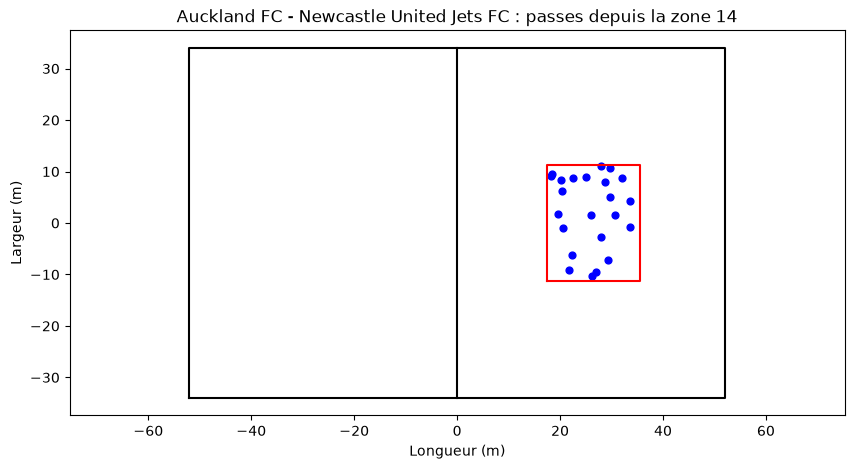

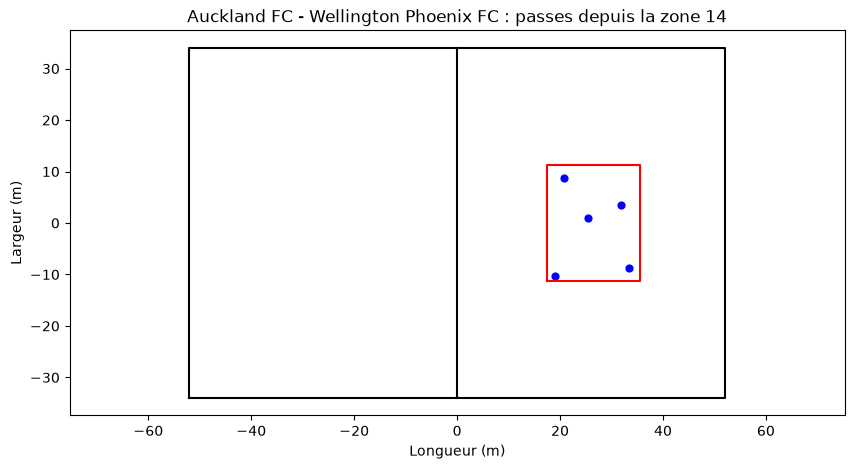

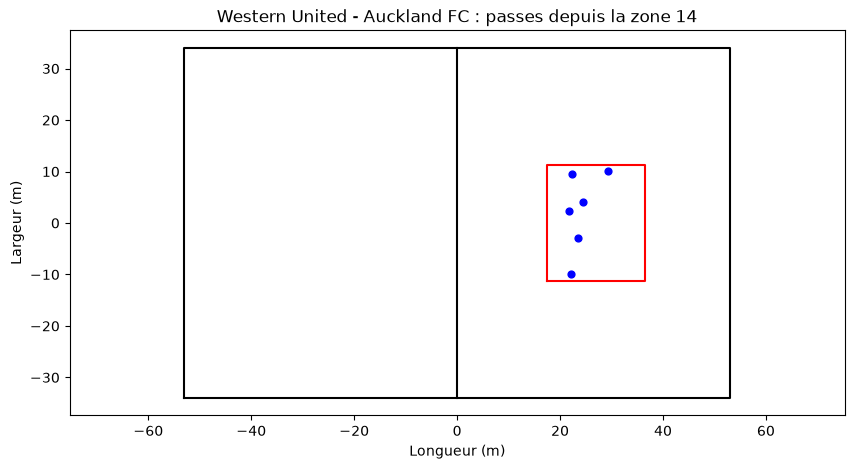

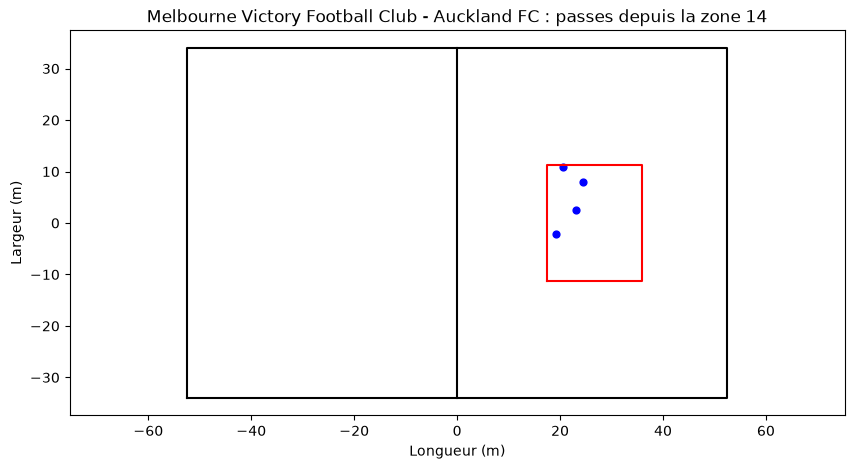

In [ ]:
#on représente les points de départ des passes sur chaque match
for nom, (infos, events) in matchs.items():
    carte_actions(infos, resultats_passes_depuis[nom],
                  nom + ' : passes depuis la zone 14', 'passes_depuis')

### Représentation des passes

La fonction `carte_actions()` appelle `tracer_terrain()` puis affiche les positions des passes avec `plt.scatter()`. Pour le type passes_depuis, les coordonnées utilisées sont `x_end` et `y_end`. Un point représente un événement retenu par le filtre, sans renseigner sa destination.

La boucle sur matchs produit une carte par rencontre en réutilisant la même méthode et les mêmes critères de sélection. Le titre précise le match et la nature des actions représentées.

## 5. Frappes depuis la zone 14

La fonction `frappes_depuis_zone14()` applique le même principe de filtrage que pour les passes, en retenant cette fois les possessions dont `end_type` vaut `shot`. Le test `dans_zone14()` est appliqué aux coordonnées de fin de possession pour localiser l'origine de la frappe.

Dans le notebook, les résultats sont stockés dans un dictionnaire distinct. Un tableau résume le nombre de frappes sélectionnées et la moyenne de `possession_epv_for_end`, calculée avec `mean()`. Cette variable décrit la valeur `EPV` associée à la fin de la possession, encore une fois elle ne doit pas être assimilée à la probabilité de réussite du tir.

Pour les cartes, `carte_actions()` utilise `plt.scatter()` avec les coordonnées `x_end` et `y_end` et un symbole de couleur différente. Le changement de couleur permet de distinguer visuellement les types d'événements sans modifier leur définition.

In [ ]:
resultats_frappes = {}
for nom, (infos, events) in matchs.items():
    resultats_frappes[nom] = frappes_depuis_zone14(infos, events, id_auckland)

lignes = []
for nom, df in resultats_frappes.items():
    lignes.append({
        'Match': nom,
        'Frappes depuis Z14': len(df),
        'EPV fin de possession': df['possession_epv_for_end'].mean()
    })

pd.DataFrame(lignes).round(3)

,Match,Frappes depuis Z14,EPV fin de possession
0,Auckland FC - Newcastle United Jets FC,6,0.091
1,Auckland FC - Wellington Phoenix FC,4,0.105
2,Western United - Auckland FC,2,0.076
3,Melbourne Victory Football Club - Auckland FC,4,0.156


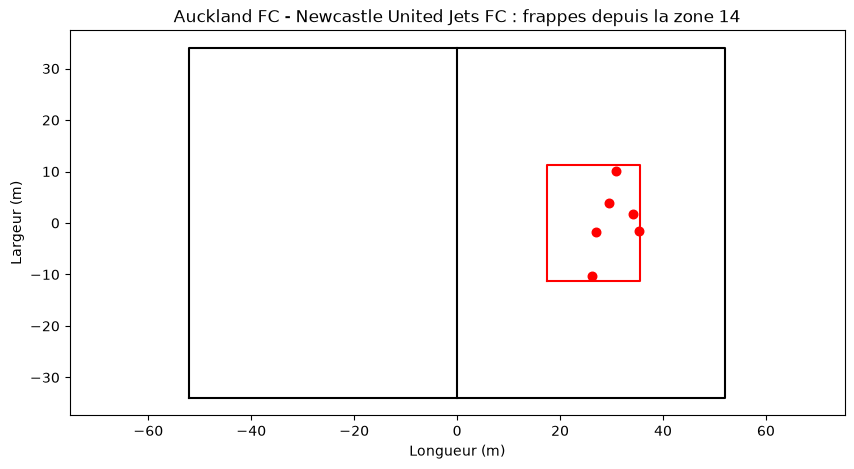

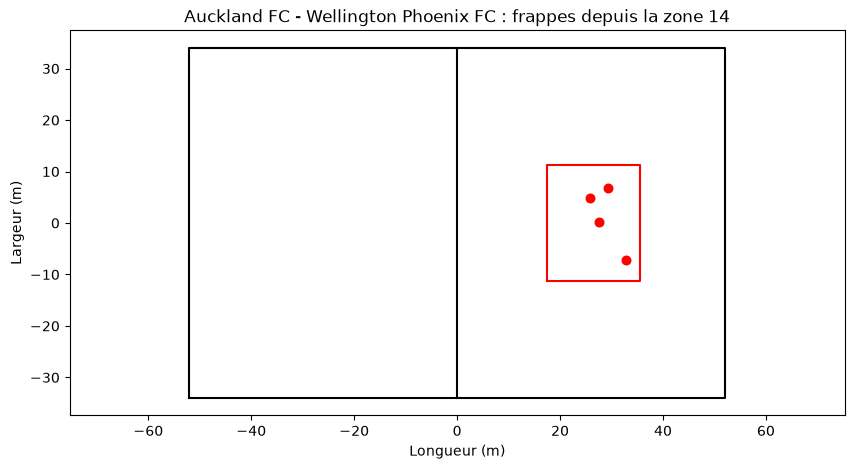

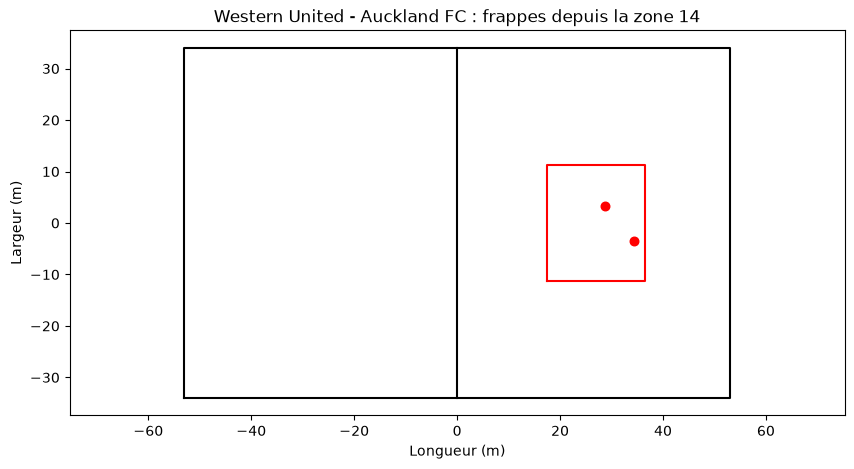

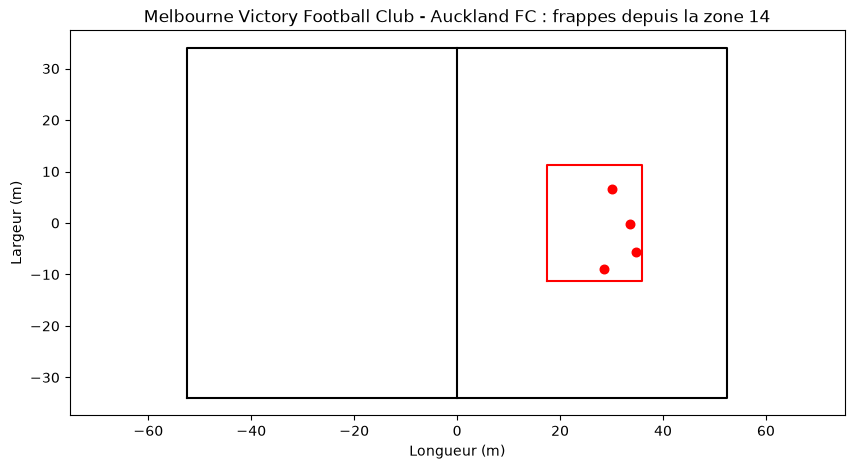

In [ ]:
for nom, (infos, events) in matchs.items():
    carte_actions(infos, resultats_frappes[nom],
                  nom + ' : frappes depuis la zone 14', 'frappes')

## 6. Estimation des passes vers la zone 14

### 6.1. Principe et choix méthodologiques

Nous cherchons les passes d’Auckland qui partent de l’extérieur de la zone 14 et semblent être reçues à l’intérieur. Dans ces données, `x_end` et `y_end` indiquent la position du passeur à la fin de sa possession, et non celle du receveur. Nous estimons donc la réception grâce au début de la possession individuelle suivante (`x_start`, `y_start`).

La fonction `passes_vers_zone14()` retient une action lorsque la première possession se termine par une passe d’Auckland et que la suivante appartient aussi à Auckland, concerne un autre joueur, commence entre 0 et 30 frames (3 secondes) après la passe et ne traverse pas la mi-temps. Enfin, la position du passeur doit être hors de la zone 14, et celle du receveur estimé à l’intérieur.

Le seuil de 30 frames est une hypothèse méthodologique pour éviter d’associer des événements trop éloignés. Cette méthode ne prouve pas que la seconde possession résulte directement de la passe, les réceptions restent estimées.

### 6.2. Explication du code Python

Après la préparation des données et le filtrage des événements `player_possession` avec `.loc[]`, `sort_values()` les classe chronologiquement. `reset_index(drop=True)` réinitialise les indices pour aligner deux tableaux : `iloc[:-1]` contient les possessions actuelles et `iloc[1:]` les suivantes. On ajoute alors à la première ligne les informations de la possession suivante, sous des noms distincts (`joueur_suivant`, `frame_suivante`, `x_arrivee`, `y_arrivee`, etc.).

La différence `frame_suivante - frame_end` fournit `ecart_frames`. Les filtres Pandas utilisent `&` pour exiger plusieurs conditions et `~` pour inverser le test d’appartenance à la zone. Le dernier filtre conserve ainsi une arrivée dans la zone 14, mais un départ hors de celle-ci. `.copy()` renvoie un tableau indépendant des données initiales.

### 6.3. Application aux matchs

Une boucle `for` applique la fonction aux quatre rencontres. Les résultats sont enregistrés dans le dictionnaire `resultats_passes_vers`, puis `len()` permet de compter les passes estimées dans un tableau comparatif.

In [ ]:
resultats_passes_vers = {}
for nom, (infos, events) in matchs.items():
    resultats_passes_vers[nom] = passes_vers_zone14(infos, events, id_auckland)

lignes = []
for nom, df in resultats_passes_vers.items():
    lignes.append({'Match': nom, 'Passes vers Z14 (estimées)': len(df)})

pd.DataFrame(lignes).round(2)

,Match,Passes vers Z14 (estimées)
0,Auckland FC - Newcastle United Jets FC,11
1,Auckland FC - Wellington Phoenix FC,10
2,Western United - Auckland FC,4
3,Melbourne Victory Football Club - Auckland FC,5


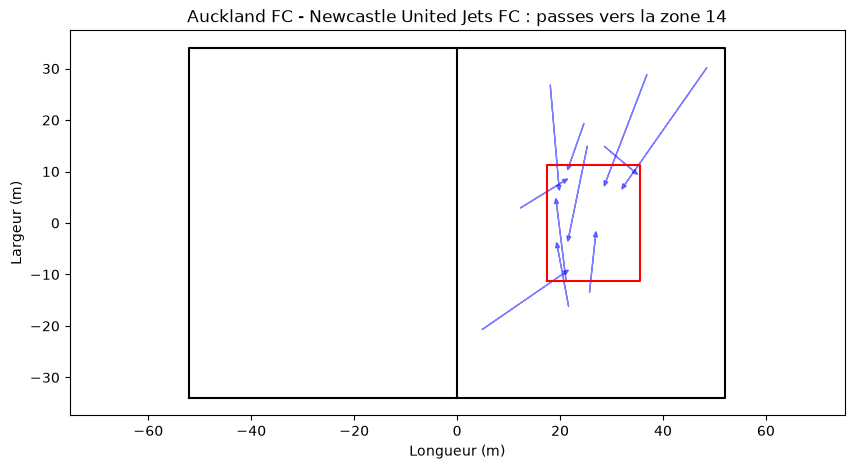

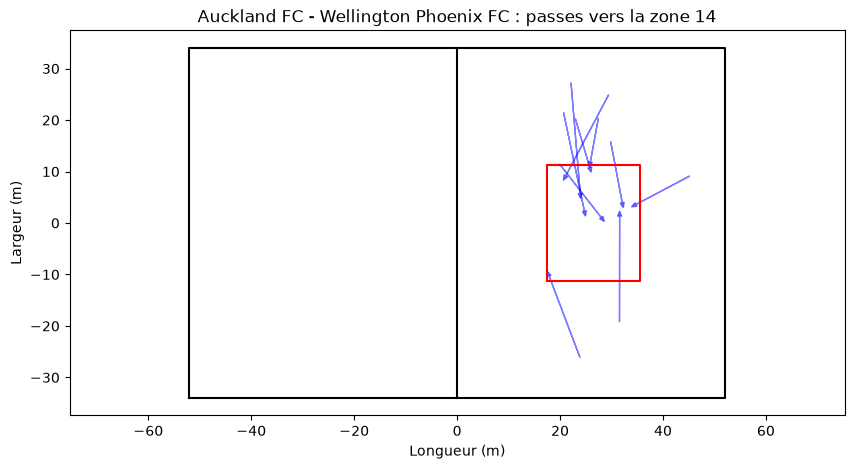

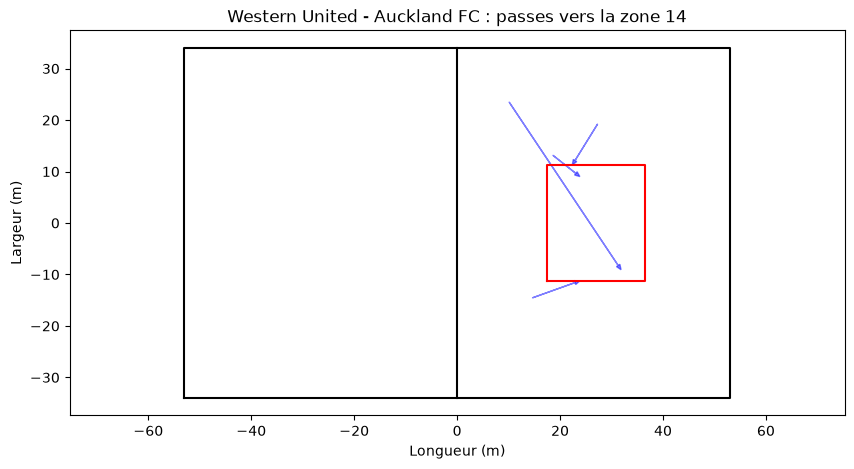

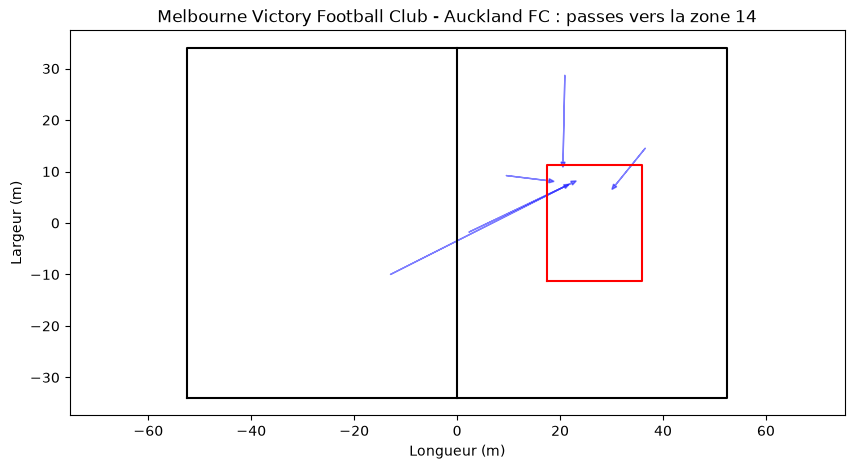

In [ ]:
for nom, (infos, events) in matchs.items():
    carte_actions(infos, resultats_passes_vers[nom],
                  nom + ' : passes vers la zone 14', 'passes_vers')

## 7. Courses sans ballon vers et depuis la zone 14

Les fonctions `courses_vers_zone14()` et `courses_depuis_zone14()` commencent par sélectionner les événements de type `off_ball_run` appartenant à Auckland. Contrairement aux passes estimées, ces événements disposent directement de coordonnées de début et de fin de course.

Pour les courses vers la zone 14, le filtre retient les actions dont le départ est hors de la zone et l'arrivée à l'intérieur. Pour les courses depuis la zone 14, le départ doit se trouver à l'intérieur et l'arrivée à l'extérieur. L'opérateur ~ sert à inverser le test d'appartenance à la zone, et & combine les deux conditions.

Ces définitions comptabilisent les courses qui traversent la frontière de la zone 14 selon leurs extrémités. Elles ne comptent pas les courses dont le début et la fin sont tous deux dans la zone, elles ne permettent pas non plus de savoir si le joueur a reçu le ballon pendant son déplacement.

Le notebook crée deux dictionnaires de résultats, un par sens de déplacement. La boucle sur les matchs et les appels à `len()` servent ensuite à construire le tableau comparatif.

In [ ]:
resultats_courses_vers = {}
resultats_courses_depuis = {}
for nom, (infos, events) in matchs.items():
    resultats_courses_vers[nom] = courses_vers_zone14(infos, events, id_auckland)
    resultats_courses_depuis[nom] = courses_depuis_zone14(infos, events, id_auckland)

lignes = []
for nom in matchs:
    lignes.append({
        'Match': nom,
        'Courses vers Z14': len(resultats_courses_vers[nom]),
        'Courses depuis Z14': len(resultats_courses_depuis[nom])
    })
pd.DataFrame(lignes).round(2)

,Match,Courses vers Z14,Courses depuis Z14
0,Auckland FC - Newcastle United Jets FC,15,51
1,Auckland FC - Wellington Phoenix FC,10,21
2,Western United - Auckland FC,22,15
3,Melbourne Victory Football Club - Auckland FC,11,14


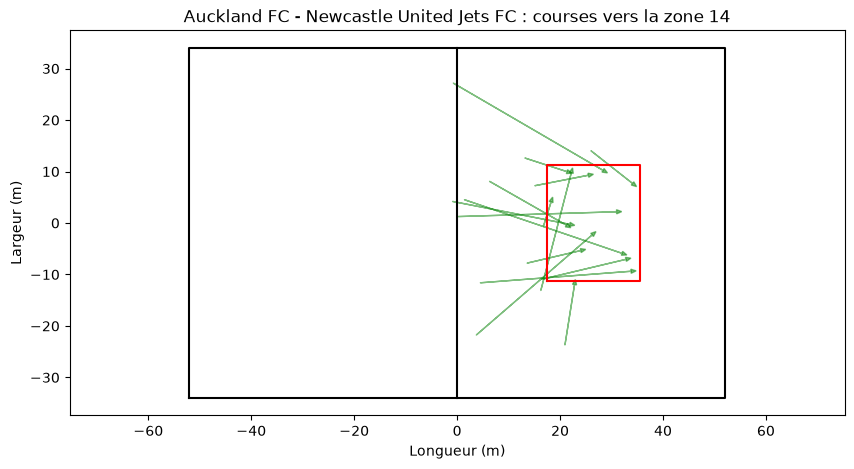

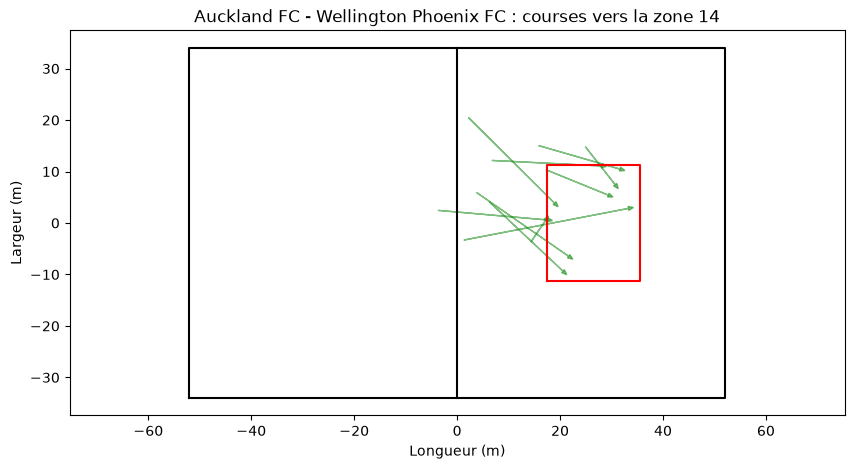

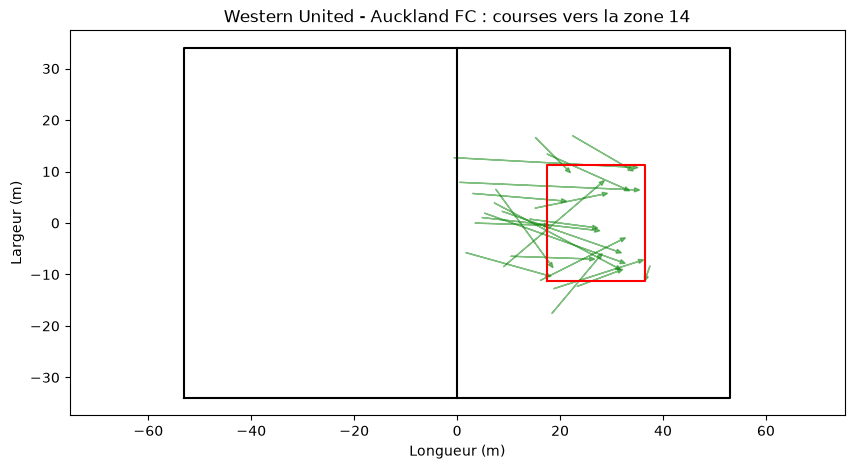

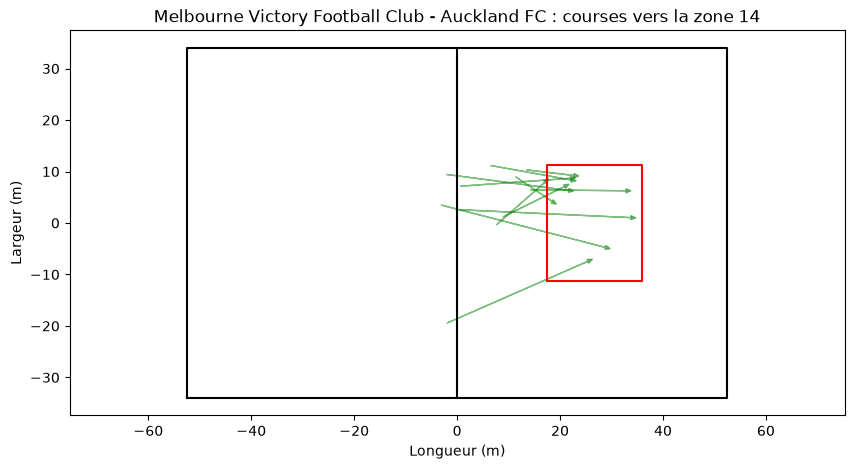

In [ ]:
for nom, (infos, events) in matchs.items():
    carte_actions(infos, resultats_courses_vers[nom],
                  nom + ' : courses vers la zone 14', 'courses')

### Représentation des courses entrantes

Pour le type courses, `carte_actions()` parcourt les événements avec `iterrows()`. Elle utilise les coordonnées `x_start` et `y_start` comme origine de la flèche, puis calcule le déplacement en soustrayant les coordonnées initiales aux coordonnées finales. L'argument `length_includes_head=True` permet d'inclure la pointe de la flèche dans la longueur représentée.

Cette carte décrit la direction des courses sélectionnées par la fonction `courses_vers_zone14()`. Elle ne fournit pas d'information sur la réception éventuelle d'une passe par le joueur.

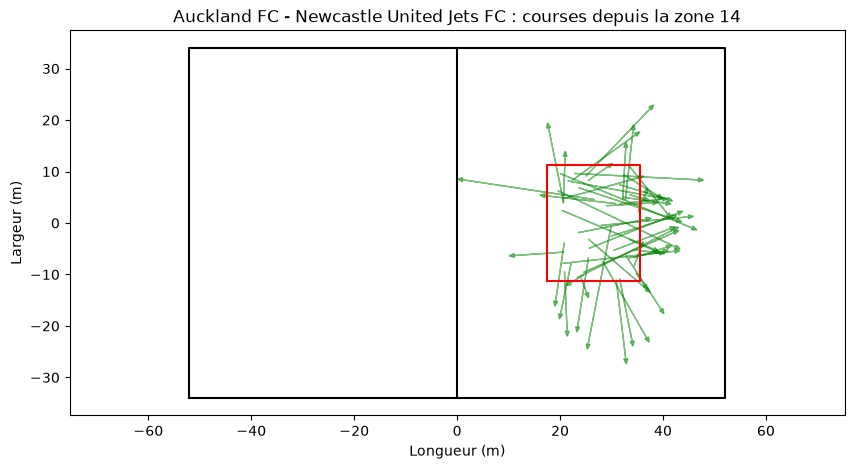

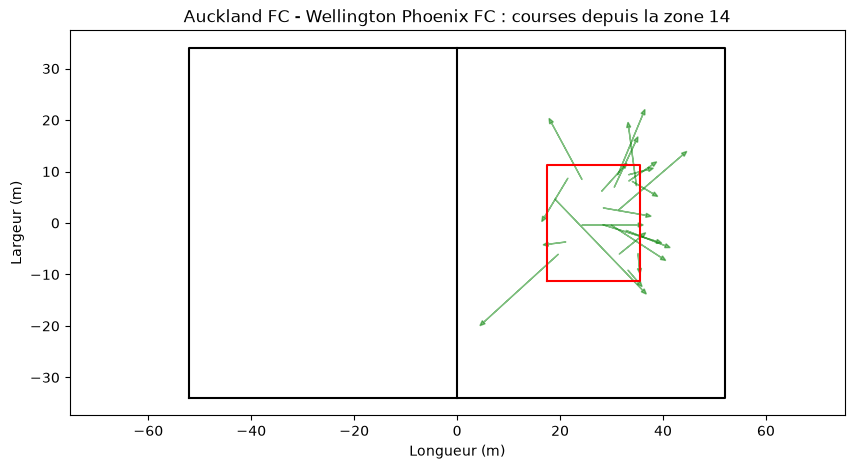

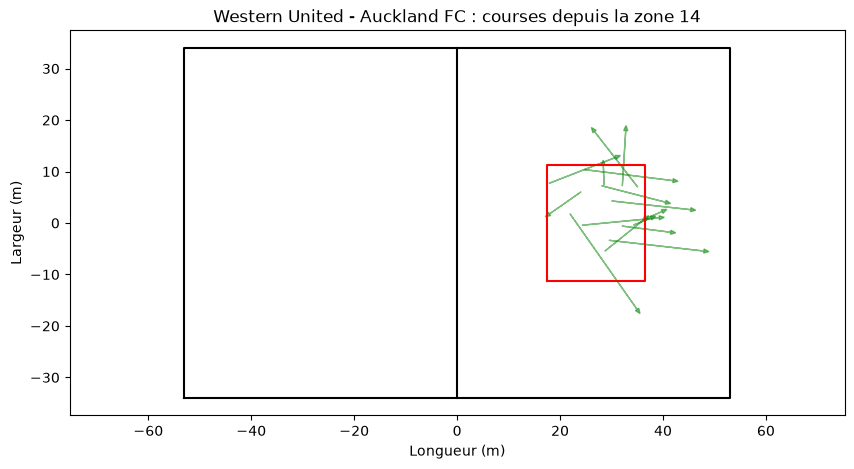

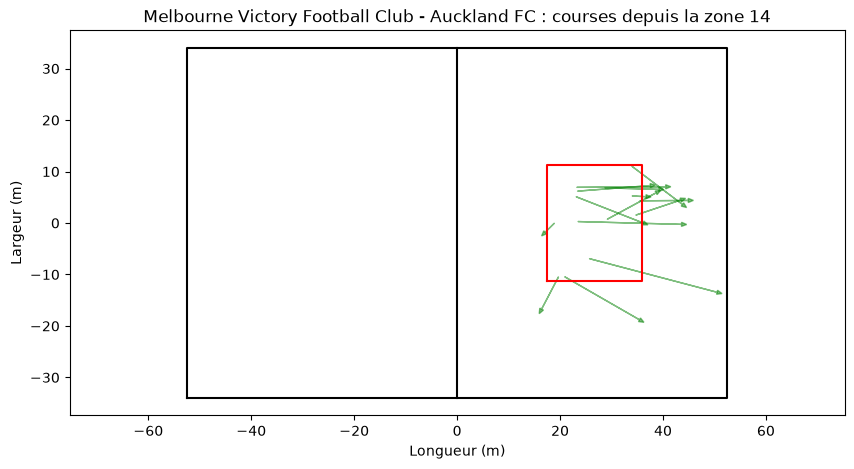

In [ ]:
for nom, (infos, events) in matchs.items():
    carte_actions(infos, resultats_courses_depuis[nom],
                  nom + ' : courses depuis la zone 14', 'courses')

### Représentation des courses sortantes

La même fonction `carte_actions()` est réutilisée pour afficher `resultats_courses_depuis`. Comme les deux types de courses possèdent les mêmes colonnes de départ et d'arrivée, il n'est pas nécessaire de créer deux fonctions de dessin différentes.



## 8. Récapitulatif méthodologique, bilan et limites

### Organisation du programme

Le script `src/fonctions_zone14.py` contient trois catégories de fonctions :

- Préparation et géométrie : `bornes_zone14()`, `dans_zone14()` et `preparer_evenements()` définissent la zone et harmonisent les données.
- Sélection des événements : `passes_depuis_zone14()`, `frappes_depuis_zone14()`, `passes_vers_zone14()`, `courses_vers_zone14()` et `courses_depuis_zone14()` isolent les actions recherchées.
- Synthèse et représentation : `bilan_match()` rassemble les indicateurs ; `tracer_terrain()` et `carte_actions()` produisent les graphiques.

Le notebook importe ces fonctions, parcourt les rencontres avec des boucles, stocke les résultats dans des dictionnaires, assemble des listes de dictionnaires en DataFrames et affiche les tableaux et cartes. Cette séparation facilite la réutilisation et évite de recopier les mêmes filtres à plusieurs endroits.

### Bilan 

Cette analyse met en évidence des différences dans l'utilisation de la zone 14 par Auckland FC selon les rencontres. Le match contre Newcastle Jets se distingue notamment par un nombre plus important de passes, de frappes et de courses depuis cette zone. Auckland semble donc y avoir été particulièrement actif lors de cette rencontre. Cependant, une utilisation plus fréquente de la zone 14 ne signifie pas nécessairement une valeur offensive plus élevée. Par exemple, Auckland réalise davantage de frappes depuis cette zone contre Newcastle (6), mais l'EPV moyen en fin de possession est plus élevé contre Melbourne Victory (0,156). La comparaison des passes et des courses vers la zone 14 est également intéressante. Contre Western United, Auckland effectue 22 courses vers la zone, mais seulement 4 passes y aboutissent selon notre estimation. Cela suggère un décalage entre les déplacements des joueurs et les passes réalisées dans cette zone. À l'inverse, les matchs contre Newcastle et Wellington présentent davantage de passes vers la zone 14.

### Limites 

L'étude repose sur quatre matchs et ne constitue donc pas une mesure représentative de l'ensemble de la saison. Les résultats dépendent de la définition géométrique de la zone, de la disponibilité des événements SkillCorner et des critères de filtrage retenus. La position utilisée pour identifier une passe depuis la zone correspond à la fin de possession du joueur. Les passes vers la zone sont estimées à partir de la possession suivante, elles ne reposent pas sur une liaison vérifiée entre passeur et receveur. Les courses sans ballon et les passes ne sont pas appariées individuellement, de sorte qu'on ne peut pas calculer un taux de courses effectivement servies à partir des deux seuls effectifs. Les variables EPV mesurent une valeur offensive estimée associée aux événements et ne sont pas des xG. Les moyennes doivent toujours être rapportées au nombre d'actions retenues. Enfin, les conversions de types avec astype() supposent que les données sont convertibles, et la fonction de dessin devrait imposer une échelle égale sur les deux axes pour représenter les distances sans déformation. Les commentaires sur les différences de performances d'Auckland entre les matchs, ainsi que leur mise en relation avec les scores, sont volontairement réservés au notebook synthèse.
